# 03 · Ballenas y flujo de órdenes

**Objetivo:** pasar de velas a **operaciones individuales** para ver *quién*
mueve el mercado: el tamaño real de cada orden, si compra o vende de forma
agresiva y cómo se comporta el dinero grande frente al pequeño.

**Datos:** 7 días completos de `aggTrades` de BTCUSDT (15-21 nov 2026)
descargados con `btc-trades` desde data.binance.vision, verificados con su
SHA-256.

**Contenido**
1. Qué es un aggTrade
2. Validación: ¿están todas las operaciones?
3. De aggTrades a órdenes reales
4. Distribución de tamaños: ¿cuánto pesa el dinero grande?
5. ¿Qué es una ballena? Umbral
6. Flujo por tamaño de orden
7. Ballenas en el gráfico y CVD
8. ¿Las ballenas anticipan el precio?
9. Conclusiones y limitaciones

## 1. Qué es un aggTrade

Cada vez que una orden **agresiva** (a mercado, *taker*) cruza contra órdenes
pasivas del libro (*maker*), Binance registra la ejecución. Un **aggTrade**
agrupa las ejecuciones de una misma orden agresiva **al mismo precio** y en el
mismo instante.

| Columna | Significado |
|---|---|
| `time` | Instante de la ejecución (UTC, precisión de microsegundos) |
| `price`, `quantity` | Precio y cantidad en BTC |
| `n_trades` | Ejecuciones individuales agrupadas |
| `compra_agresiva` | `True` si el agresor compró; `False` si vendió |

En el archivo original el lado viene como `is_buyer_maker` ("el comprador era
el pasivo"), que es justo lo contrario de "compra agresiva". El cliente lo
invierte al cargar para evitar confusiones.

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.io as pio
import seaborn as sns
from scipy.stats import spearmanr

from btc_radar.agg_trades import cargar_trades, ultimos_dias
from btc_radar.ballenas import (
    agrupar_ordenes,
    cvd,
    delta_usd,
    detectar_ballenas,
    flujo_por_tamano,
    umbral_ballena,
    velas_desde_trades,
)
from btc_radar.datos import cargar_velas
from btc_radar.graficos import grafico_ballenas

pio.renderers.default = "plotly_mimetype+png"
sns.set_theme(style="whitegrid")

dias = ultimos_dias(7, hasta=date(2026, 11, 22))
trades = cargar_trades(dias)
print(f"{len(trades):,} aggTrades del {dias[0]} al {dias[-1]}")
trades.head()

9,919,115 aggTrades del 2026-11-15 al 2026-11-21


,agg_trade_id,time,price,quantity,n_trades,compra_agresiva
0,4117417531,2026-11-15 00:00:00.020558+00:00,64150.01,0.003,1,True
1,4117417532,2026-11-15 00:00:00.020896+00:00,64150.01,0.003,1,True
2,4117417533,2026-11-15 00:00:00.034839+00:00,64150.01,0.002,1,True
3,4117417534,2026-11-15 00:00:00.170592+00:00,64150.00,0.003,1,False
4,4117417535,2026-11-15 00:00:00.173160+00:00,64150.00,0.003,1,False


## 2. Validación: ¿están todas las operaciones?

Dos comprobaciones independientes:
1. **IDs consecutivos:** `agg_trade_id` es correlativo; un salto indicaría
   operaciones perdidas.
2. **Cuadre con las velas:** la suma de cantidades por día debe coincidir con el
   volumen de la vela diaria descargada en la Fase 1 (fuente distinta: la API).

In [2]:
saltos = (trades["agg_trade_id"].diff().dropna() != 1).sum()
print(f"Saltos en agg_trade_id: {saltos}")

velas_1d = cargar_velas("1d")
dia = trades["time"].dt.floor("D")
compras = trades[trades["compra_agresiva"]]
cuadre = pd.DataFrame(
    {
        "volumen trades": trades.groupby(dia)["quantity"].sum(),
        "volumen velas": velas_1d["volume"],
        "compra trades": compras.groupby(dia[compras.index])["quantity"].sum(),
        "compra velas": velas_1d["taker_buy_volume"],
    }
).dropna()
cuadre["dif. volumen %"] = (
    cuadre["volumen trades"] / cuadre["volumen velas"] - 1
) * 100
cuadre["dif. compra %"] = (cuadre["compra trades"] / cuadre["compra velas"] - 1) * 100
cuadre.round(3)

Saltos en agg_trade_id: 0


,volumen trades,volumen velas,compra trades,compra velas,dif. volumen %,dif. compra %
2026-11-15 00:00:00+00:00,29231.160,29231.160,13224.046,13224.046,0.0,0.0
2026-11-16 00:00:00+00:00,21929.236,21929.236,11262.170,11262.170,0.0,0.0
2026-11-17 00:00:00+00:00,28316.763,28316.763,15598.701,15598.701,0.0,0.0
2026-11-18 00:00:00+00:00,18699.696,18699.696,9415.078,9415.078,-0.0,0.0
2026-11-19 00:00:00+00:00,19879.640,19879.640,9339.066,9339.066,0.0,0.0
2026-11-20 00:00:00+00:00,38125.926,38125.926,17224.832,17224.832,0.0,0.0
2026-11-21 00:00:00+00:00,48558.101,48558.101,22529.434,22529.434,0.0,-0.0


**Lectura:** no falta ningún ID y el volumen total y el comprador cuadran
con las velas al 0,000 %. Tenemos **todas** las operaciones de la semana.

## 3. De aggTrades a órdenes reales

Una orden grande a mercado "barre" varios niveles del libro y queda registrada
como **un aggTrade por nivel**, todos con el mismo microsegundo y el mismo lado.
Si se analizan aggTrades sueltos, una orden de 5 M USD parece muchas pequeñas.
`agrupar_ordenes` vuelve a unirlas.

In [3]:
ordenes = agrupar_ordenes(trades)
print(
    f"{len(trades):,} aggTrades → {len(ordenes):,} órdenes "
    f"({len(ordenes) / len(trades):.0%})"
)

columnas = [
    "time",
    "usd",
    "cantidad",
    "compra_agresiva",
    "niveles",
    "precio_min",
    "precio_max",
]
ordenes.nlargest(8, "usd")[columnas].round({"usd": 0, "cantidad": 1})

9,919,115 aggTrades → 5,126,284 órdenes (52%)


,time,usd,cantidad,compra_agresiva,niveles,precio_min,precio_max
1836544,2026-11-17 13:07:48.855497+00:00,6784586.0,104.1,True,370,65120.01,65184.01
2708881,2026-11-19 03:34:52.713608+00:00,6410654.0,101.7,True,3,63059.98,63060.00
2808760,2026-11-19 11:34:27.315921+00:00,6380485.0,99.6,True,1,64060.00,64060.00
7603,2026-11-15 00:09:16.244751+00:00,6349739.0,99.3,True,1,63950.00,63950.00
2513371,2026-11-18 17:28:03.062158+00:00,6326670.0,100.0,True,425,63208.44,63322.28
2750459,2026-11-19 06:28:12.216761+00:00,6289777.0,99.0,True,1,63560.00,63560.00
3825564,2026-11-20 17:40:22.126656+00:00,5716724.0,96.9,True,1,59000.00,59000.00
2820770,2026-11-19 12:25:20.704829+00:00,5511914.0,86.5,False,1,63730.00,63730.00


**Lectura:** la agrupación reduce las filas casi a la mitad. La orden más
grande de la semana (6,8 M USD, ~104 BTC) consumió **370 niveles de precio** en
un solo instante. Sin agrupar, habría aparecido como 370 operaciones medianas.

*Supuesto:* dos agresores distintos ejecutando en el mismo microsegundo y del
mismo lado se contarían como una sola orden. Es poco frecuente y no altera las
conclusiones.

## 4. Distribución de tamaños: ¿cuánto pesa el dinero grande?

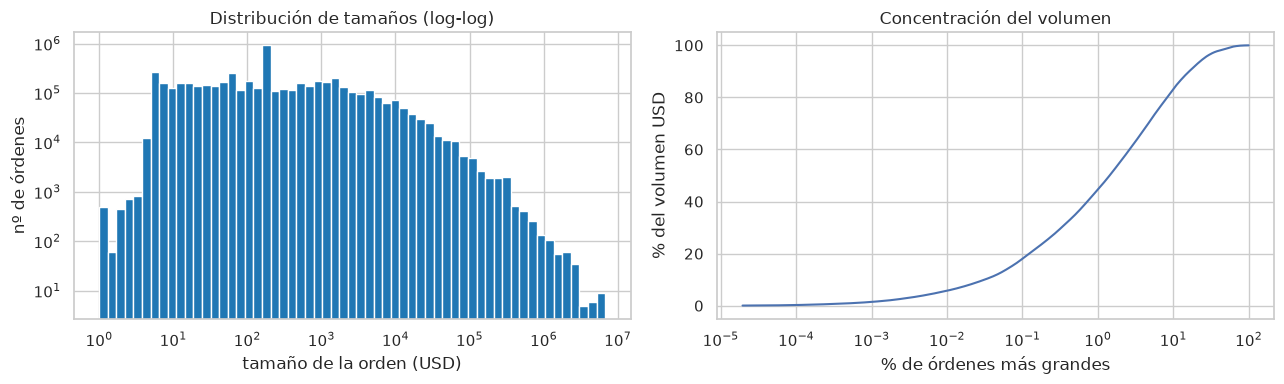

Mediana: 191 USD por orden


,% del volumen USD
top 0.1 %,18.0 %
top 1 %,44.6 %
top 10 %,83.2 %


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

bins = np.logspace(0, np.log10(ordenes["usd"].max()), 60)
axes[0].hist(ordenes["usd"], bins=bins, color="tab:blue")
axes[0].set(
    xscale="log",
    yscale="log",
    xlabel="tamaño de la orden (USD)",
    ylabel="nº de órdenes",
    title="Distribución de tamaños (log-log)",
)

ordenado = ordenes["usd"].sort_values(ascending=False).to_numpy()
pct_ordenes = np.arange(1, len(ordenado) + 1) / len(ordenado) * 100
pct_volumen = ordenado.cumsum() / ordenado.sum() * 100
axes[1].plot(pct_ordenes, pct_volumen)
axes[1].set(
    xscale="log",
    xlabel="% de órdenes más grandes",
    ylabel="% del volumen USD",
    title="Concentración del volumen",
)
plt.tight_layout()
plt.show()

print(f"Mediana: {ordenes['usd'].median():,.0f} USD por orden")
pd.Series(
    {
        f"top {p} %": f"{pct_volumen[int(len(ordenado) * p / 100) - 1]:.1f} %"
        for p in (0.1, 1, 10)
    }
).to_frame("% del volumen USD")

**Lectura:** muchísimas órdenes diminutas (mediana ≈ 190 USD) y unas pocas
enormes. Entre ~5 y ~1.000 USD la distribución es casi plana, con picos en
tamaños redondos (~5 y ~200 USD), probablemente órdenes automatizadas o mínimos
de la plataforma. A partir de ~1.000 USD cae casi en línea recta en log-log:
una **cola pesada** de tipo ley de potencias. El **0,1 % de las órdenes más grandes mueve ~18 % del volumen**, y el
1 % más grande, casi la mitad.

## 5. ¿Qué es una ballena? Umbral

Dos criterios complementarios:
- **Relativo (percentil 99,9):** el 0,1 % de órdenes más grandes del periodo. Se
  adapta a cada época del mercado.
- **Absoluto (≥ 1 M USD):** fácil de comunicar y estable entre periodos.

In [5]:
umbral = umbral_ballena(ordenes, percentil=0.999)
ballenas = detectar_ballenas(ordenes, percentil=0.999)
ballenas_1m = detectar_ballenas(ordenes, umbral_usd=1e6)


def resumen(grupo: pd.DataFrame, umbral_usd: float) -> list:
    return [
        f"{umbral_usd:,.0f}",
        len(grupo),
        f"{grupo['compra_agresiva'].mean():.1%}",
        f"{delta_usd(grupo).sum() / 1e6:+.1f}",
    ]


pd.DataFrame(
    {
        "percentil 99,9": resumen(ballenas, umbral),
        "≥ 1 M USD": resumen(ballenas_1m, 1e6),
    },
    index=["umbral (USD)", "órdenes", "% compras", "delta neto (M USD)"],
)

,"percentil 99,9",≥ 1 M USD
umbral (USD),"232,036","1,000,000"
órdenes,5127,300
% compras,49.7%,50.0%
delta neto (M USD),+94.1,+40.6


## 6. Flujo por tamaño de orden

¿Quién compra y quién vende? `delta %` es el delta del grupo sobre su volumen:
+100 % si todo fue compra agresiva, −100 % si todo fue venta agresiva.

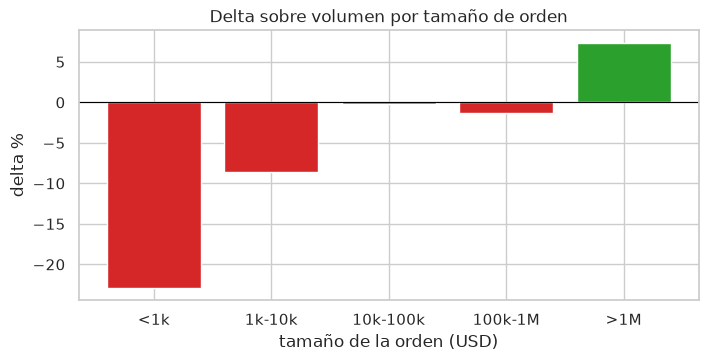

Precio: 64,150 → 60,216 (mínimo 55,130)


,órdenes,volumen (M USD),% del volumen,delta (M USD),delta %
tamano,,,,,
<1k,3883277,693.6,5.5,-158.7,-22.9
1k-10k,1009527,3171.8,25.0,-271.1,-8.5
10k-100k,219852,5318.8,41.9,-7.5,-0.1
100k-1M,13328,2947.1,23.2,-39.9,-1.4
>1M,300,551.6,4.3,40.6,7.4


In [6]:
flujo = flujo_por_tamano(ordenes)
tabla = pd.DataFrame(
    {
        "órdenes": flujo["ordenes"],
        "volumen (M USD)": flujo["volumen_usd"] / 1e6,
        "% del volumen": flujo["volumen_pct"] * 100,
        "delta (M USD)": flujo["delta_usd"] / 1e6,
        "delta %": flujo["delta_pct"] * 100,
    }
)

fig, ax = plt.subplots(figsize=(8, 3.5))
colores = np.where(tabla["delta %"] >= 0, "tab:green", "tab:red")
ax.bar(tabla.index.astype(str), tabla["delta %"], color=colores)
ax.axhline(0, color="black", lw=0.8)
ax.set(
    title="Delta sobre volumen por tamaño de orden",
    xlabel="tamaño de la orden (USD)",
    ylabel="delta %",
)
plt.show()

print(
    f"Precio: {trades['price'].iloc[0]:,.0f} → {trades['price'].iloc[-1]:,.0f} "
    f"(mínimo {trades['price'].min():,.0f})"
)
tabla.round(1)

**Lectura:** en una semana en la que BTC cayó de ~64.000 a ~60.000 (con
mínimo en 55.130 el 21-nov):
- Las órdenes **pequeñas** fueron claramente **vendedoras**: −23 % del volumen
  en las de menos de 1.000 USD y −8,5 % entre 1k y 10k.
- Las órdenes medianas y grandes (10k-1M) quedaron prácticamente equilibradas.
- Las órdenes de **más de 1 M USD** fueron **compradoras netas** (+7 %).

Es el patrón que la teoría Wyckoff describe como **absorción**: el público vende
con miedo y el dinero grande recoge esa oferta. Con una sola semana es una
observación, no una regla; la Fase 5 buscará este patrón de forma sistemática.

## 7. Ballenas en el gráfico y CVD

**CVD** (*Cumulative Volume Delta*): suma acumulada de compras agresivas menos
ventas agresivas. Si baja, dominan los vendedores agresivos.

Se representan las órdenes ≥ 1 M USD (300) para que el gráfico sea legible.

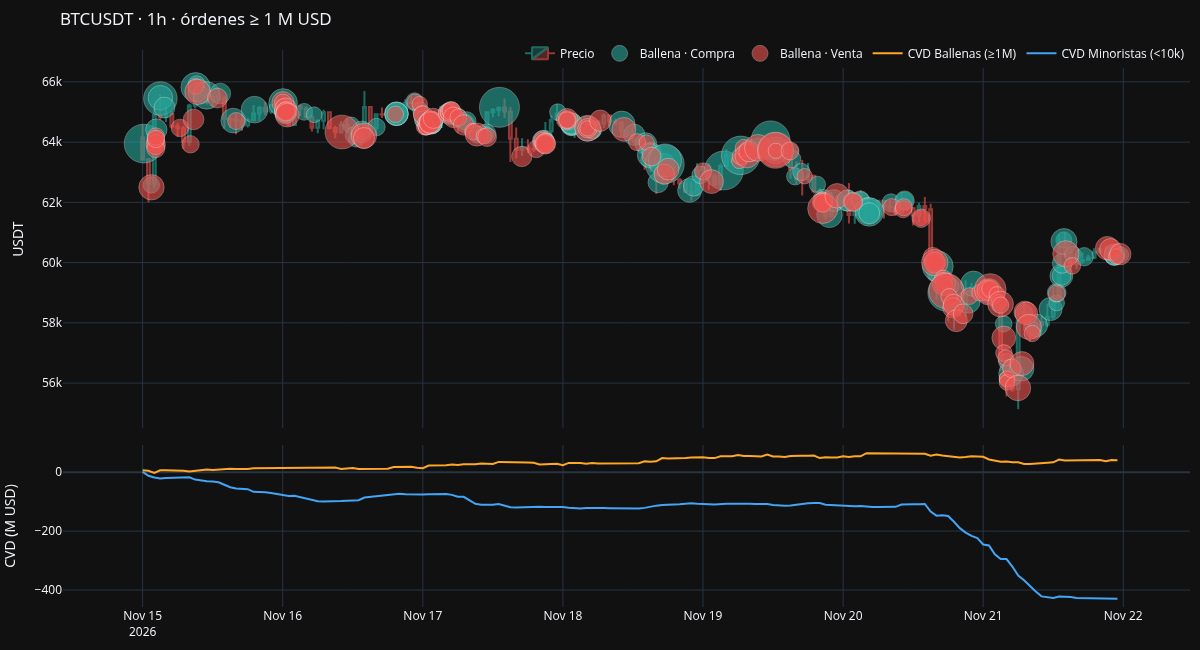

In [7]:
velas_1h = velas_desde_trades(trades, "1h")
minoristas = ordenes[ordenes["usd"] < 1e4]
cvds = {"Ballenas (≥1M)": cvd(ballenas_1m), "Minoristas (<10k)": cvd(minoristas)}

grafico_ballenas(velas_1h, ballenas_1m, cvds, "BTCUSDT · 1h · órdenes ≥ 1 M USD").show(
    width=1200, height=650
)

**Lectura:**
- El CVD de los **minoristas** cae toda la semana y se desploma en la caída del
  20-21 de noviembre (≈ −430 M USD).
- El CVD de las **ballenas** se mantiene plano o ligeramente positivo.
- En el **mínimo** del 21-nov también aparecen ventas grandes (burbujas rojas):
  hubo capitulación también entre el dinero grande. El **rebote** posterior
  arranca con compras grandes (burbujas verdes).

## 8. ¿Las ballenas anticipan el precio?

Test por horas: correlación de rangos (Spearman) entre el delta de cada grupo
en una hora y el retorno **de esa misma hora** y **de la hora siguiente**.

In [8]:
precio = velas_1h["close"]
retorno = np.log(precio).diff()


def delta_horario(grupo: pd.DataFrame) -> pd.Series:
    serie = delta_usd(grupo).set_axis(grupo["time"]).resample("1h").sum()
    return serie.reindex(precio.index, fill_value=0)


filas = {}
for nombre, grupo in [
    ("ballenas (p99,9)", ballenas),
    ("minoristas (<10k)", minoristas),
]:
    delta = delta_horario(grupo)
    mismo = spearmanr(delta, retorno, nan_policy="omit")
    siguiente = spearmanr(delta, retorno.shift(-1), nan_policy="omit")
    filas[nombre] = {
        "ρ misma hora": round(mismo.statistic, 2),
        "p misma hora": f"{mismo.pvalue:.1g}",
        "ρ hora siguiente": round(siguiente.statistic, 2),
        "p hora siguiente": round(siguiente.pvalue, 2),
    }
print(f"Horas analizadas: {retorno.notna().sum()}")
pd.DataFrame(filas).T

Horas analizadas: 167


,ρ misma hora,p misma hora,ρ hora siguiente,p hora siguiente
"ballenas (p99,9)",0.31,4e-05,-0.03,0.72
minoristas (<10k),0.17,0.03,-0.14,0.07


**Lectura:**
- El flujo de las ballenas **acompaña** al precio en la misma hora (ρ ≈ 0,3,
  significativo): cuando compran, el precio sube en esa hora.
- Pero **no anticipa** la hora siguiente (ρ ≈ 0, p-valor alto).
- El flujo minorista muestra una ligera relación inversa con la hora siguiente
  que no llega a ser significativa al 5 %.

Con ~167 horas la muestra es corta: el resultado indica que **no hay una
ventaja evidente** siguiendo a las ballenas a 1 hora, no que nunca la haya.

## 9. Conclusiones y limitaciones

**Conclusiones**
1. **Datos completos y validados:** 9,9 M de aggTrades sin huecos, que cuadran
   exactamente con las velas.
2. **Agrupar en órdenes es necesario:** reduce las filas a la mitad y revela
   órdenes de hasta 6,8 M USD que barren cientos de niveles.
3. **Cola pesada:** el 0,1 % de las órdenes mueve ~18 % del dinero.
4. **Divergencia por tamaño:** en la caída, los minoristas vendieron y las
   órdenes > 1 M USD compraron en neto (absorción).
5. **Sin ventaja predictiva directa** del flujo de ballenas a 1 hora.

**Limitaciones**
- Solo Binance **spot**: no incluye futuros (donde se negocia más volumen) ni
  otros exchanges.
- Una semana de datos: los hallazgos son descriptivos.
- Las órdenes **pasivas** grandes (muros del libro) no aparecen en las
  operaciones; requieren el libro de órdenes (fase opcional 9).

**Siguiente paso → Fase 5:** detectar rangos y eventos Wyckoff por reglas,
usando volumen, volatilidad y el flujo de órdenes como evidencia.